# 06 · Hedge units, basis risk & stress

What does the estimated beta mean in dollars, shares, and possible hedge failure?

Run this notebook from top to bottom. It is independent of the execution state of other notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from btc_nasdaq.config import project_root, load_config
from btc_nasdaq.research import research_context, run_period
from btc_nasdaq.plotting import set_theme, save_figure, shade_holdout, PALETTE
from btc_nasdaq.data import sha256

set_theme()
pd.options.display.float_format = "{:,.4f}".format
ROOT = project_root()
c = research_context(ROOT)
cfg, prices, returns = c["cfg"], c["prices"], c["returns"]
betas, beta, signal = c["betas"], c["beta"], c["signal"]
HOLDOUT = cfg["validation"]["holdout_start"]
summary_path = ROOT / "reports/tables/summary.json"
if not summary_path.exists():
    raise RuntimeError("Run uv run python scripts/run_research.py before executing the notebooks.")
run_record = json.loads(summary_path.read_text())
if (run_record["config_sha256"] != sha256(ROOT / "configs/research.toml") or
    run_record["data_sha256"] != sha256(ROOT / "data/processed/aligned_prices.parquet")):
    raise RuntimeError("Summary tables are stale. Re-run scripts/run_research.py.")
display(Markdown(f"**Data:** {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d} "
                 f"· **{len(prices):,} synchronized sessions** · BTC-USD / QQQ · "
                 f"**Fixed baseline:** {cfg['strategy']['model']}"))

**Data:** 2018-01-02 to 2026-11-06 · **2,225 synchronized sessions** · BTC-USD / QQQ · **Fixed baseline:** ewma_63

## Convert return beta to signed units

For BTC units $q_B$, spot $P_B$, hedge mark $P_H$, and contract multiplier M:

$$D_B=q_BP_B,\qquad D_H=-\hat\beta D_B,\qquad q_H=\frac{-\hat\beta q_BP_B}{MP_H}.$$

Use **raw QQQ price** for shares; adjusted close belongs in returns, not order quantities.
Positive units mean long. A negative estimated beta can require a same-direction hedge. The
nearest integer is a sizing illustration; liquidity, borrow and risk limits can require another rounding rule.

For futures, multiply index points by the contract multiplier. CME currently specifies
[MNQ at $2 per Nasdaq-100 point](https://www.cmegroup.com/markets/equities/nasdaq/micro-e-mini-nasdaq-100.contractSpecs.html).
The QQQ beta cannot be assumed to be a calibrated futures beta; basis and roll effects need a new fit.
The futures price below is an explicitly hypothetical input, not a fetched contract quote.

,btc_notional,hedge_notional,hedge_units,nearest_whole_units,rounding_residual_beta_dollars,gross_notional,net_notional
1 BTC long / QQQ proxy,"75,769.9400","-67,102.5926",-102.2750,-102.0000,180.3951,"142,872.5326","8,667.3474"
1 BTC short / QQQ proxy,"-75,769.9400","67,102.5926",102.2750,102.0000,-180.3951,"142,872.5326","-8,667.3474"
"1 BTC long / hypothetical MNQ at 20,000","75,769.9400","-67,102.5926",-1.6776,-2.0000,"-12,897.4074","142,872.5326","8,667.3474"


**Historical marks:** 2026-11-06; beta 0.886. One BTC is an illustrative position size, not a recommendation. No live quotes, locates or margin checks are included.

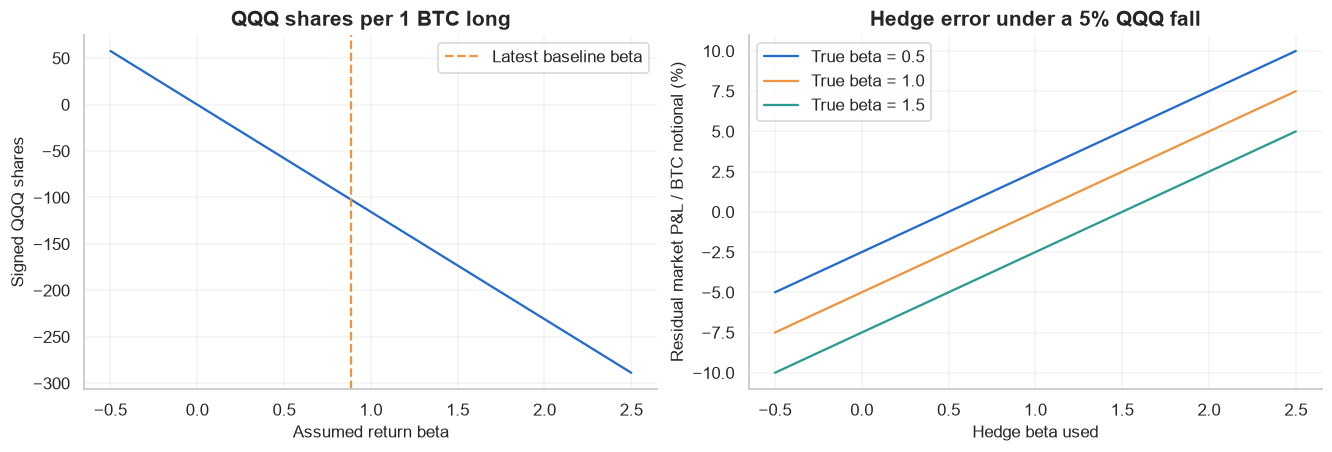

In [2]:
from btc_nasdaq.risk import hedge_units, stress_scenarios
latest = prices.iloc[-1]
b = float(beta.dropna().iloc[-1])
illustration = {
    "1 BTC long / QQQ proxy": hedge_units(1., latest.btc, latest.qqq_raw, b),
    "1 BTC short / QQQ proxy": hedge_units(-1., latest.btc, latest.qqq_raw, b),
    "1 BTC long / hypothetical MNQ at 20,000": hedge_units(1., latest.btc, 20_000., b, multiplier=2.),
}
display(pd.DataFrame(illustration).T)
display(Markdown(f"**Historical marks:** {prices.index[-1]:%Y-%m-%d}; beta {b:.3f}. "
                 "One BTC is an illustrative position size, not a recommendation. No live quotes, locates or margin checks are included."))
grid = np.linspace(-.5, 2.5, 101)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(grid, -grid * latest.btc / latest.qqq_raw)
axes[0].axvline(b, color=PALETTE[1], linestyle="--", label="Latest baseline beta")
axes[0].set(title="QQQ shares per 1 BTC long", xlabel="Assumed return beta", ylabel="Signed QQQ shares")
axes[0].legend()
for true_beta in [.5, 1., 1.5]:
    axes[1].plot(grid, (true_beta-grid)*(-.05)*100, label=f"True beta = {true_beta:.1f}")
axes[1].set(title="Hedge error under a 5% QQQ fall", xlabel="Hedge beta used", ylabel="Residual market P&L / BTC notional (%)")
axes[1].legend()
plt.show()

,btc_return,qqq_return,unhedged,half_size_unhedged,hedged
scenario,,,,,
BTC-specific recovery,0.1000,0.0000,0.1000,0.0500,0.1000
Broad risk selloff,-0.1500,-0.0800,-0.1500,-0.0750,-0.0792
Crypto-only crash,-0.2500,0.0000,-0.2500,-0.1250,-0.2500
QQQ squeeze / BTC flat,0.0000,0.1000,0.0000,0.0000,-0.0886
Correlation flips,-0.1500,0.0500,-0.1500,-0.0750,-0.1943
Weekend BTC gap / QQQ stale,-0.1200,0.0000,-0.1200,-0.0600,-0.1200


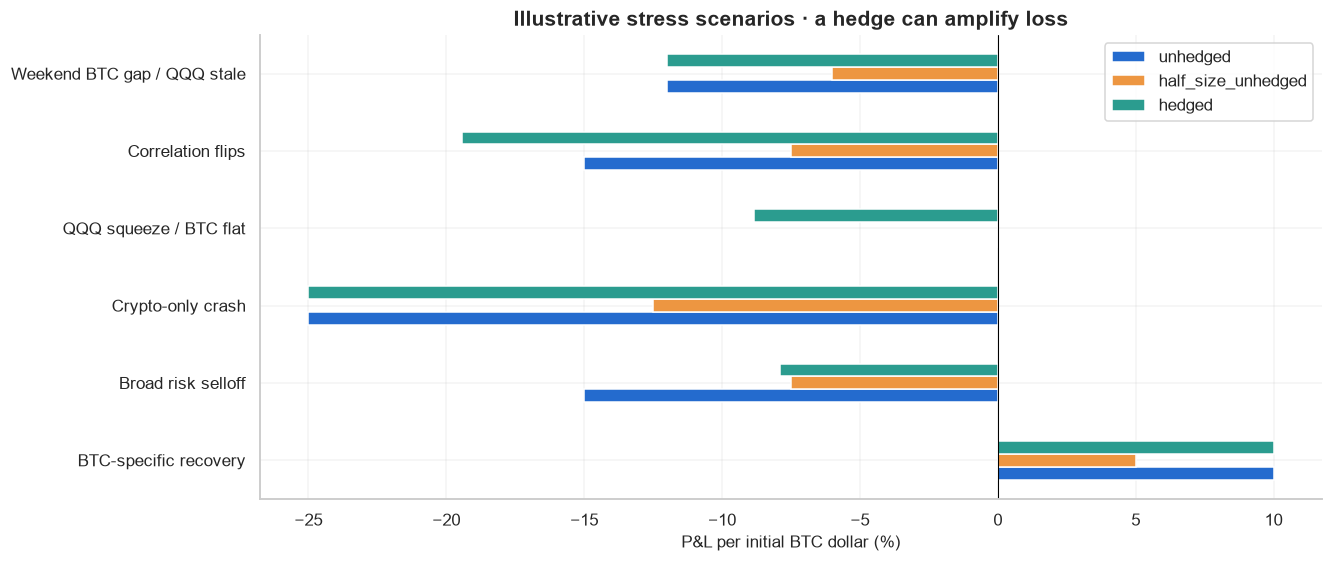

In [3]:
scenarios = stress_scenarios(b)
display(scenarios)
fig, ax = plt.subplots(figsize=(12, 5))
(scenarios[["unhedged", "half_size_unhedged", "hedged"]]*100).plot.barh(ax=ax)
ax.axvline(0, color="black", lw=.7)
ax.set(title="Illustrative stress scenarios · a hedge can amplify loss", xlabel="P&L per initial BTC dollar (%)", ylabel="")
save_figure(fig, ROOT, "06_hedge_failure_scenarios")
plt.show()

## What stays in the position?

| Exposure | Treatment | Research implication |
| --- | --- | --- |
| BTC-specific reversal | Intentionally retained | Needs delayed predictive evidence and positive net economics |
| Linear QQQ beta | Estimated and hedged | Check residual beta and conditional downside behavior |
| Crypto jumps / venue / stablecoin stress | Retained | Nasdaq may provide no protection |
| Weekend/holiday crypto moves | Retained while QQQ closed | No intraperiod rehedging; gaps can cross stop levels |
| QQQ–futures basis and roll | Unmodeled in this pass | Fit the actual traded hedge before using futures |
| Borrow / financing / funding | Stylized costs only | Check real terms; BTC short access is not assumed executable |
| Nonlinear and other factor exposures | Retained | Consider market/rates/dollar factors and tail dependence next |
| Liquidity and margin | No capacity model | Smaller exposure or no trade can be preferable to a poor hedge |

**Research monitoring triggers:** inspect a 63-session realized residual correlation outside ±0.2,
a 20-session beta change above 0.5, a data-quality failure, or materially higher carry. These thresholds
are review prompts, not calibrated risk limits. Re-estimate when the instrument or holding horizon changes.

**Implementation readiness:** research only. The immediate next step is stronger alpha evidence and
contract/venue-specific execution data, not opening the displayed position.

In [4]:
# Optional interactive calculator; open in JupyterLab to change historical sizing assumptions.
import ipywidgets as widgets
@widgets.interact(btc_units=widgets.FloatSlider(value=1., min=-5., max=5., step=.25, description="BTC units"),
                  hedge_beta=widgets.FloatSlider(value=round(b, 2), min=-1., max=4., step=.05, description="Beta"))
def sizing_calculator(btc_units, hedge_beta):
    display(pd.Series(hedge_units(btc_units, latest.btc, latest.qqq_raw, hedge_beta), name="Historical QQQ illustration"))

interactive(children=(FloatSlider(value=1.0, description='BTC units', max=5.0, min=-5.0, step=0.25), FloatSlid…

---
**Research notes / feedback**

- Observation worth following up:
- Assumption to change in the next experiment:
- Evidence that would change the conclusion:

Record changes in `docs/research_log.md`. Once you inspect a holdout, it is no longer untouched data for a new variant.